<a href="https://colab.research.google.com/github/Subhana-sheikh/Marks-Hours-Linear-Regression/blob/main/MarksHours.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

In [ ]:
model = LinearRegression()

In [ ]:
url = "https://docs.google.com/spreadsheets/d/1ZDPNgTskttsCCYiggxnwQf32w5ObW8L3n9DEyYVsztU/export?format=xlsx"
df = pd.read_excel(url)
df.head()

,Hours,Marks
0,2,40
1,3,50
2,4,55
3,5,65
4,6,70


In [ ]:
df.tail()

,Hours,Marks
46,4,60
47,5,68
48,2,44
49,3,50
50,4,52


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Hours   51 non-null     int64
 1   Marks   51 non-null     int64
dtypes: int64(2)
memory usage: 948.0 bytes


In [ ]:
df.describe()

,Hours,Marks
count,51.000000,51.000000
mean,5.254902,63.862745
std,2.841430,21.066580
min,1.000000,30.000000
25%,3.000000,47.500000
50%,5.000000,60.000000
75%,7.000000,76.500000
max,10.000000,100.000000


In [ ]:
X = df[["Hours"]]
X

,Hours
0,2
1,3
2,4
3,5
4,6
5,7
6,8
7,4
8,5
9,6


In [ ]:
type(X)

pandas.core.frame.DataFrame

In [ ]:
y= df["Marks"]

In [ ]:
type(y)

pandas.core.series.Series

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [ ]:
model= LinearRegression()

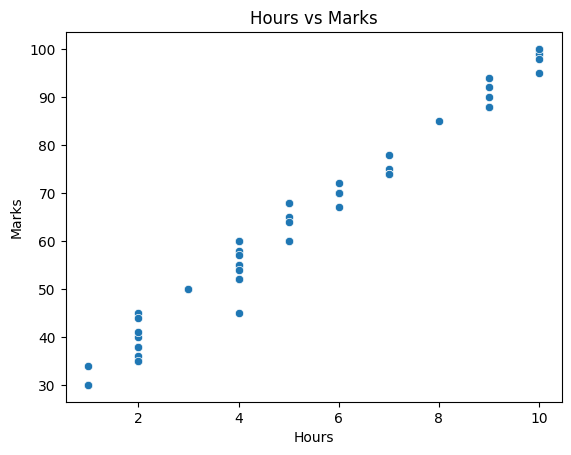

In [ ]:
sns.scatterplot(data = df, x='Hours',y='Marks')
plt.xlabel("Hours")
plt.ylabel("Marks")
plt.title("Hours vs Marks")
plt.show()

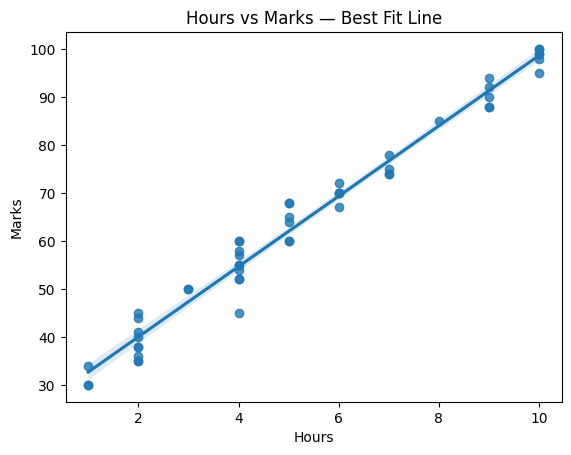

In [ ]:
sns.regplot(x='Hours', y='Marks', data=df)
plt.xlabel("Hours")
plt.ylabel("Marks")
plt.title("Hours vs Marks — Best Fit Line")
plt.show()

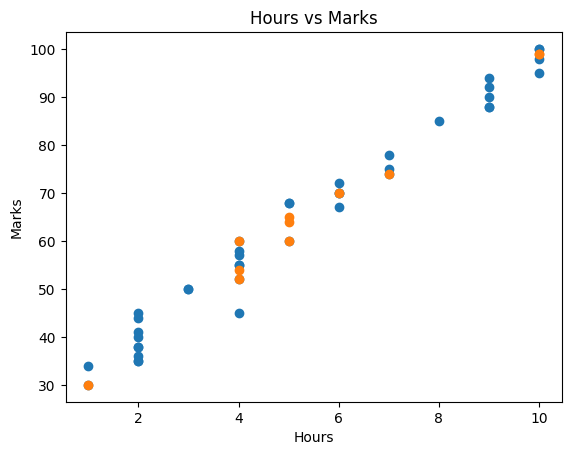

In [ ]:
plt.plot(X_train,y_train,"o")
plt.plot(X_test,y_test,"o")
plt.xlabel("Hours")
plt.ylabel("Marks")
plt.title("Hours vs Marks")
plt.show()

In [ ]:
model.fit(X_train,y_train)

LinearRegression()

In [ ]:
prediction = model.predict([[9]])
print(prediction)

[91.19893]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
prediction = model.predict([[2]])
print(prediction)

[40.05056137]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
prediction = model.predict([[0.1]])
print(prediction)

[26.16743275]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
prediction = model.predict([[1]])
print(prediction)

[32.74365157]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
prediction = model.predict([[9000]])
print(prediction)

[65787.62497174]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [ ]:
predicted=model.predict(X_test)

In [ ]:
X_test

,Hours
43,5
40,4
46,4
12,5
24,10
31,6
17,1
32,10
3,5
30,7


In [ ]:
predicted

array([61.97129078, 54.66438098, 54.66438098, 61.97129078, 98.5058398 ,
       69.27820059, 32.74365157, 98.5058398 , 61.97129078, 76.58511039,
       54.66438098])

In [ ]:
comparison = pd.DataFrame({
    "Actual": y_test,
    "Predicted": predicted
})

comparison

,Actual,Predicted
43,64,61.971291
40,54,54.664381
46,60,54.664381
12,60,61.971291
24,99,98.505840
31,70,69.278201
17,30,32.743652
32,99,98.505840
3,65,61.971291
30,74,76.585110


Actual: Student ke real marks.

Predicted: Model ke predicted marks.


Error: Actual aur predicted marks ka difference.

In [ ]:
comparison["Error"] = comparison["Actual"] - comparison["Predicted"]
print(comparison)

    Actual  Predicted     Error
43      64  61.971291  2.028709
40      54  54.664381 -0.664381
46      60  54.664381  5.335619
12      60  61.971291 -1.971291
24      99  98.505840  0.494160
31      70  69.278201  0.721799
17      30  32.743652 -2.743652
32      99  98.505840  0.494160
3       65  61.971291  3.028709
30      74  76.585110 -2.585110
13      52  54.664381 -2.664381


##Actual vs Predicted graph

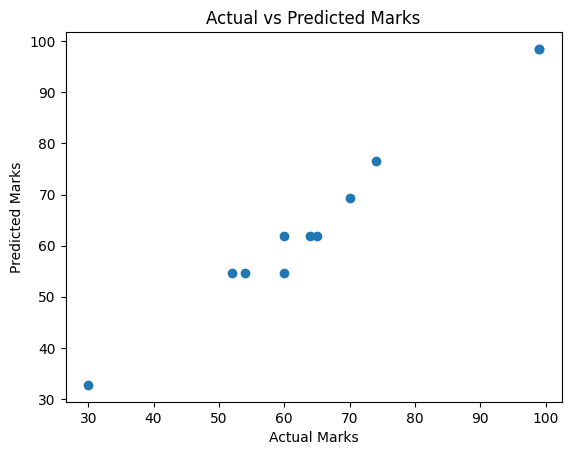

In [ ]:
plt.scatter(y_test, predicted)
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.show()

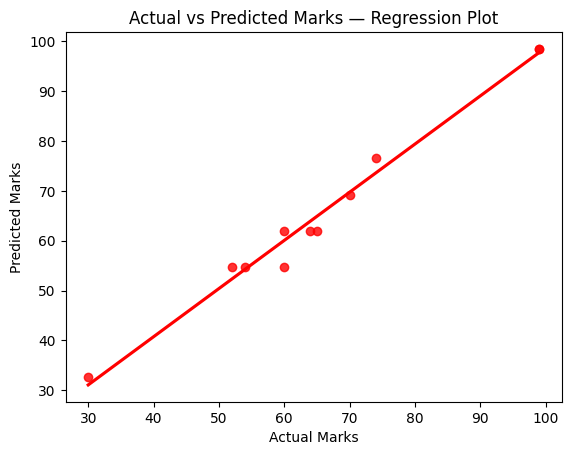

In [ ]:
sns.regplot(x=y_test, y=predicted, ci=None, color ='red')
plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks — Regression Plot")
plt.show()

##Model kitna achha hai?--R^2 Score

In [ ]:
print("R² Score:", r2_score(y_test, predicted))

R² Score: 0.9827737962583313


Coefficient (slope): Study hours 1 unit badhne par predicted marks kitne badlenge.

Intercept: Jab study hours 0 honge, tab model kitne marks predict karega.

Coefficient aur Intercept :

In [ ]:
print("Coefficient:", model.coef_)
print("Intercept:", model.intercept_)

Coefficient: [7.3069098]
Intercept: 25.436741767764296


Linear Regression ka formula hai:
- y = mx + c

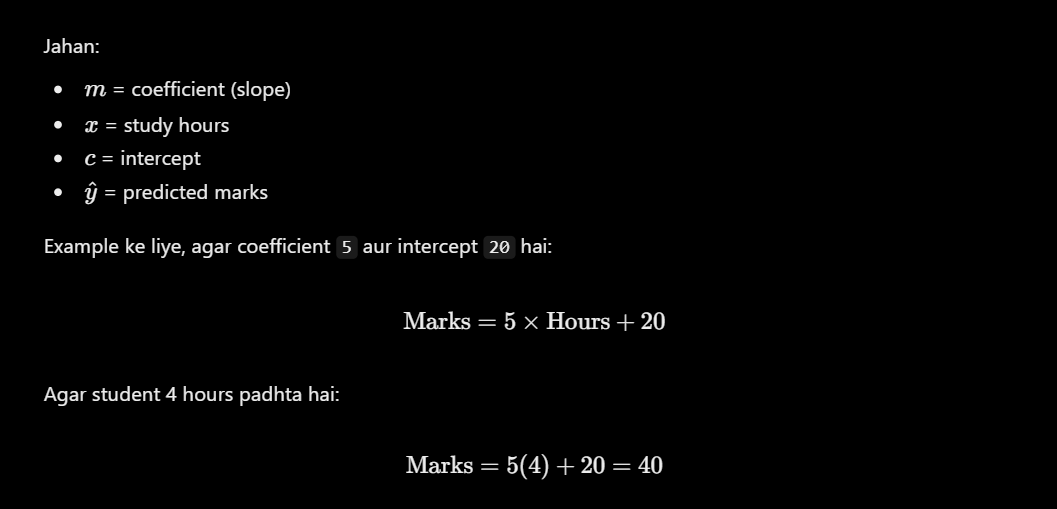